In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm  # Use notebook-friendly tqdm
import os
import json

# Import your project's modules
from config import config, device
from model import FeatureExtractor, Encoder, Decoder
from dataset import CaptionDataset

# Set Matplotlib to display plots inline
%matplotlib inline

print(f"Using device: {device}")

Using device: cuda


using cuda - pytorch uses CUDA to accelerate tensor operations and model training 
### Data preprocessing and Tokenization

In [2]:
with open(config.path_to_txt, "r") as file:
    raw_lines = file.readlines()
print(f"Found {len(raw_lines)} total caption entries.")
print("Example raw line:", raw_lines[0].strip())

Found 40456 total caption entries.
Example raw line: image,caption


### parse and group captions by image 

In [3]:
caption_mapping = {}
images_to_skip = set()

for line in raw_lines:
    line = line.rstrip("\n")
    img_name, caption = line.split(",",1)
    img_name = img_name.split("#")[0]
    img_name = os.path.join(config.images_path, img_name)
    
    # Filter out captions that are too long or too short
    tokens = caption.strip().split()
    if len(tokens) < 5 or len(tokens) > config.maxlen:
        images_to_skip.add(img_name)
        continue

    # Add special <start> and <end> tokens
    caption = "<start> " + caption.strip() + " <end>"

    if img_name in caption_mapping:
        caption_mapping[img_name].append(caption)
    else:
        caption_mapping[img_name] = [caption]

# Remove images that had bad captions
for img_name in images_to_skip:
    if img_name in caption_mapping:
        del caption_mapping[img_name]

print(f"\nProcessed {len(caption_mapping)} unique images.")
# Let's inspect the captions for one image
example_image_path = list(caption_mapping.keys())[0]
print(f"\nExample captions for image '{os.path.basename(example_image_path)}':")
for cap in caption_mapping[example_image_path]:
    print(f"  - {cap}")


Processed 7733 unique images.

Example captions for image '1000268201_693b08cb0e.jpg':
  - <start> A child in a pink dress is climbing up a set of stairs in an entry way . <end>
  - <start> A girl going into a wooden building . <end>
  - <start> A little girl climbing into a wooden playhouse . <end>
  - <start> A little girl climbing the stairs to her playhouse . <end>
  - <start> A little girl in a pink dress going into a wooden cabin . <end>


### ploting 5 random images with their captions 

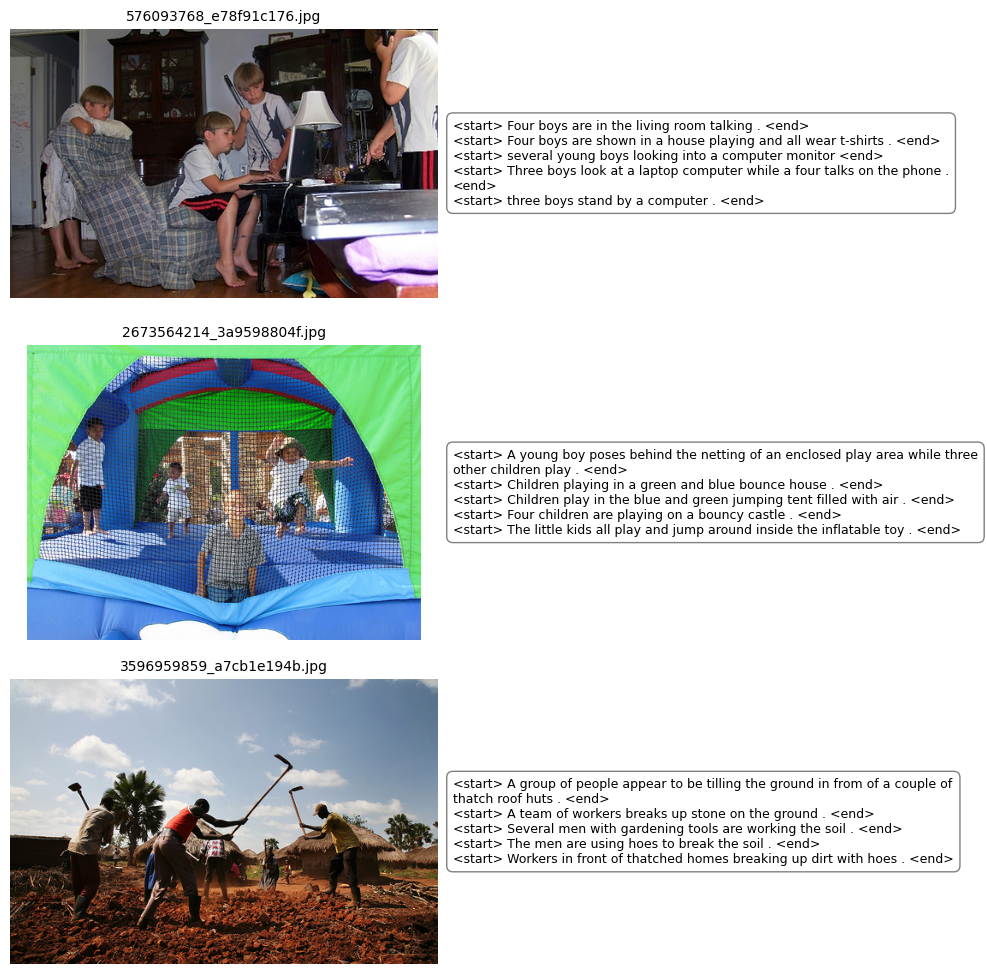

In [4]:
import random
from PIL import Image
import matplotlib.pyplot as plt

sample_images = random.sample(list(caption_mapping.keys()), 3)

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 10))

for i, img_path in enumerate(sample_images):
  
    img = Image.open(img_path)
    axes[i, 0].imshow(img)
    axes[i, 0].axis('off')
    axes[i, 0].set_title(os.path.basename(img_path), fontsize=10)
    
    captions = "\n".join([cap for cap in caption_mapping[img_path]])
    axes[i, 1].text(0, 0.5, captions, fontsize=9, va='center', ha='left', wrap=True,
                    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray"))
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### Building Vocabulary
creating token to index mapping

In [5]:
all_captions = [cap for caps_list in caption_mapping.values() for cap in caps_list]
text_data = set()
for cap in all_captions:
    # Remove start/end tokens before adding to vocab
    tokens = cap.split()[1:-1] 
    for token in tokens:
        text_data.add(token.lower())

# Create word-to-index and index-to-word mappings
word2idx = {"<pad>": 0, "<start>": 1, "<end>": 2}
idx2word = {0: "<pad>", 1: "<start>", 2: "<end>"}

for i, token in enumerate(text_data):
    word2idx[token] = i + 3
    idx2word[i + 3] = token

# Update vocab_size in the main config object
config.vocab_size = len(word2idx)

print(f"Vocabulary created.")
print(f"Total unique tokens (vocab size): {config.vocab_size}")
print("\nExample mappings:")
print(f"  word2idx['dog'] = {word2idx.get('dog', 'Not Found')}")
print(f"  word2idx['<start>'] = {word2idx['<start>']}")
print(f"  idx2word[50] = {idx2word.get(50, 'Not Found')}")


Vocabulary created.
Total unique tokens (vocab size): 8971

Example mappings:
  word2idx['dog'] = 1774
  word2idx['<start>'] = 1
  idx2word[50] = deeps


### plotting most common words (fig1)
### plotting the overall distribution of word frequencies in vocabulary (fig2)

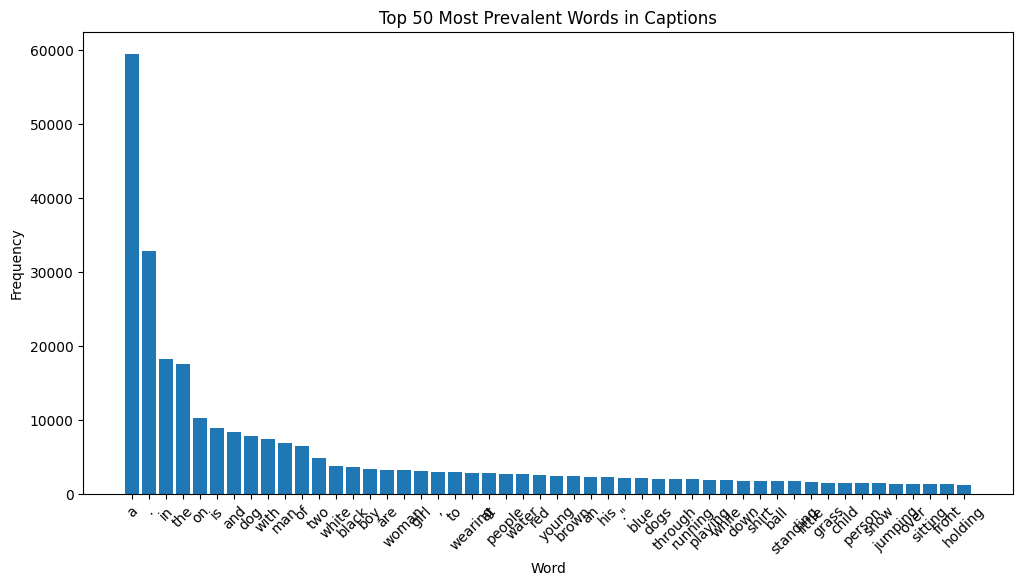

In [6]:
from collections import Counter
import matplotlib.pyplot as plt

# Count word frequencies
word_freq = Counter()
for cap in all_captions:
    tokens = cap.split()[1:-1]  # Remove <start> and <end>
    for token in tokens:
        word_freq[token.lower()] += 1

# Show top 20 most frequent words
top_n = 50
most_common = word_freq.most_common(top_n)
words, freqs = zip(*most_common)

plt.figure(figsize=(12, 6))
plt.bar(words, freqs)
plt.xticks(rotation=45)
plt.title(f"Top {top_n} Most Prevalent Words in Captions")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.show()


### create data splits and dataset

In [7]:
all_image_paths = list(caption_mapping.keys())
np.random.shuffle(all_image_paths)
train_size = int(len(all_image_paths) * 0.8)

train_paths = all_image_paths[:train_size]
valid_paths = all_image_paths[train_size:]

train_data = {path: caption_mapping[path] for path in train_paths}
valid_data = {path: caption_mapping[path] for path in valid_paths}

print(f"Data splitted into:")
print(f"  - Training samples: {len(train_data)}")
print(f"  - Validation samples: {len(valid_data)}")

#create Dataset objects
train_dataset = CaptionDataset(train_data, config, word2idx)
valid_dataset = CaptionDataset(valid_data, config, word2idx)

Data splitted into:
  - Training samples: 6186
  - Validation samples: 1547


### inspect a single data point

In [8]:
# Let's grab one item from the training set
image_tensor, captions_data = train_dataset[0]

# Extract the first caption's data from the list of 5
input_tokens_tensor, target_tokens_tensor, padding_mask = captions_data[0]

print("--- Inspecting a single data point ---")
print(f"Image Tensor Shape: {image_tensor.shape}")
print("\n--- Caption Data (for one of the 5 captions) ---")
print(f"Input Tokens (Tensor): \n{input_tokens_tensor}")
print(f"Input Tokens (Text): \n{' '.join([idx2word[idx.item()] for idx in input_tokens_tensor])}")
print(f"\nTarget Tokens (Tensor): \n{target_tokens_tensor}")
print(f"Target Tokens (Text): \n{' '.join([idx2word[idx.item()] for idx in target_tokens_tensor])}")
print(f"\nPadding Mask (True means 'ignore'): \n{padding_mask}")

--- Inspecting a single data point ---
Image Tensor Shape: torch.Size([3, 256, 256])

--- Caption Data (for one of the 5 captions) ---
Input Tokens (Tensor): 
tensor([   1, 2026, 4354, 3303,  647, 2026, 7290, 1279,  157, 7994, 5368,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0])
Input Tokens (Text): 
<start> a construction worker drills a hole into the ground . <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>

Target Tokens (Tensor): 
tensor([2026, 4354, 3303,  647, 2026, 7290, 1279,  157, 7994, 5368,    2,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0])
Target Tokens (Text): 
a construction worker drills a hole into the ground . <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>

Padding Mask (True means 'ignore'): 
tensor([False, False, False, False, False, F

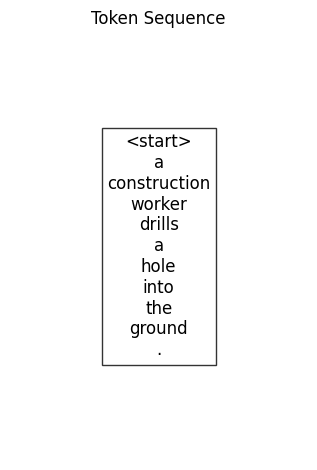


Token Details:
--------------------------------------------------
Position 0: <start> (Index: 1)
Position 1: a (Index: 2026)
Position 2: construction (Index: 4354)
Position 3: worker (Index: 3303)
Position 4: drills (Index: 647)
Position 5: a (Index: 2026)
Position 6: hole (Index: 7290)
Position 7: into (Index: 1279)
Position 8: the (Index: 157)
Position 9: ground (Index: 7994)
Position 10: . (Index: 5368)


In [9]:
# Visualize the tokenization process
plt.subplot(1, 2, 2)
# Create a more readable representation of the tokenization
tokens = [idx2word[idx.item()] for idx in input_tokens_tensor if idx != 0]  # Skip padding
token_colors = ['lightgreen' if token not in ['<start>', '<end>', '<pad>'] else 'lightgray' for token in tokens]

plt.text(0.5, 0.5, '\n'.join(tokens), 
         horizontalalignment='center',
         verticalalignment='center',
         bbox=dict(facecolor='white', alpha=0.8),
         fontsize=12)
plt.title("Token Sequence")
plt.axis('off')

plt.tight_layout()
plt.show()

# Print token information
print("\nToken Details:")
print("-" * 50)
for i, token in enumerate(tokens):
    if token not in ['<pad>']:
        print(f"Position {i}: {token} (Index: {word2idx[token]})")

### Creating DataLoaders for batching and initialize the model components

In [10]:
# --- Create DataLoaders ---
train_dataloader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=config.batch_size, shuffle=False)
print("DataLoaders created.")

# --- Initialize Models ---
feat_ext = FeatureExtractor().to(device)
encoder = Encoder(config).to(device)
decoder = Decoder(config).to(device)
print("\nModels initialized.")
# You can uncomment the line below to see the model architectures
print(encoder)

DataLoaders created.

Models initialized.
Encoder(
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ff_1): Linear(in_features=1280, out_features=2048, bias=True)
  (ff_2): Linear(in_features=2048, out_features=512, bias=True)
  (layer_norm_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  (layer_norm_2): LayerNorm((512,), eps=1e-05,

c:\Users\maryam\miniconda3\envs\med_project\Lib\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(


### visualizing model architecture 

In [11]:
from torchsummary import summary

# print("--- Feature Extractor Summary ---")
# summary(feat_ext, input_size=(3, 224, 224))

# # The encoder's input size depends on the feature extractor's output.
# # You'll need to determine this, but let's assume an example shape.
# # For instance, if feat_ext outputs a tensor of shape (batch_size, 512, 7, 7)
# print("\n--- Encoder Summary ---")
# summary(encoder, input_size=(512, 7, 7))

!python visualize_models.py

Successfully imported configuration from config.py.
Temporarily setting vocab_size to 10000 for visualization.
Device set to: cuda
TensorBoard writer initialized. Logs will be saved in 'runs/image_captioning_architecture'.
Models initialized and moved to device.
Dummy input tensors created using dimensions from your config file.
Tracing models...
✅ FeatureExtractor graph added to TensorBoard.
✅ Encoder graph added to TensorBoard.
✅ Decoder graph added to TensorBoard.

--- All Done! ---
To view the graphs, run the following command in your terminal:
tensorboard --logdir=runs


2025-08-11 21:28:50.064001: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-11 21:28:52.168403: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
c:\Users\maryam\miniconda3\envs\med_project\Lib\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(


In [12]:
!tensorboard --logdir=runs

^C


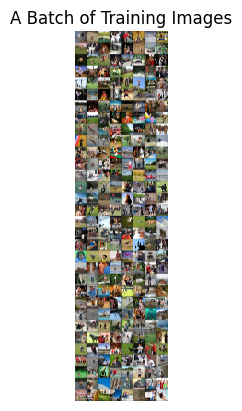

Labels for this batch: [[tensor([[   1, 1256, 5034,  ...,    0,    0,    0],
        [   1, 1256, 2854,  ...,    0,    0,    0],
        [   1, 1256, 1438,  ...,    0,    0,    0],
        ...,
        [   1, 1256, 6325,  ...,    0,    0,    0],
        [   1, 1256, 3764,  ...,    0,    0,    0],
        [   1, 1256, 3379,  ...,    0,    0,    0]]), tensor([[1256, 5034,  375,  ...,    0,    0,    0],
        [1256, 2854, 6325,  ...,    0,    0,    0],
        [1256, 1438, 6325,  ...,    0,    0,    0],
        ...,
        [1256, 6325, 5041,  ...,    0,    0,    0],
        [1256, 3764, 7395,  ...,    0,    0,    0],
        [1256, 3379, 5907,  ...,    0,    0,    0]]), tensor([[False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        ...,
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, Fa

In [ ]:
#visualize the model architecture 
import matplotlib.pyplot as plt
import numpy as np
import torchvision

# --- Get a single batch of data ---
# The iter() function creates an object that can be iterated one element at a time.
# The next() function fetches the next item from that iterator.
data_iter = iter(train_dataloader)
images, labels = next(data_iter)

# --- Create a grid of images ---
# This helper function from torchvision makes a grid from a batch of tensors.
img_grid = torchvision.utils.make_grid(images)

# --- Display the images ---
# We need to transpose the image dimensions for matplotlib
# PyTorch tensor format: (Channels, Height, Width)
# Matplotlib format: (Height, Width, Channels)
plt.imshow(img_grid.permute(1, 2, 0))
plt.title("A Batch of Training Images")
plt.axis('off') # Hide the axes
plt.show()

print(f"Labels for this batch: {labels}")

### Training Loop

In [15]:
import time
import torch
import torch.nn as nn
from tqdm import tqdm

def train_one_epoch_batched(encoder, decoder, feat_ext, dataloader, optimizer, loss_fn, causal_mask, device):
    """
    Trains the model for one epoch using gradient accumulation to save memory.
    """
    encoder.train()
    decoder.train()
    feat_ext.eval()

    total_loss = 0.0
    
    pbar = tqdm(dataloader, desc="Training", leave=False)
    for images, ys in pbar:
        images = images.to(device)
        num_captions = len(ys)

        optimizer.zero_grad()
        
        image_features = feat_ext(images)
        encoder_outputs = encoder(image_features)

        batch_loss = 0.0
        for i in range(num_captions):
            input_tokens = ys[i][0].to(device)
            tgt_tokens = ys[i][1].to(device)
            pad_mask = ys[i][2].to(device).bool()

            if causal_mask.dtype != pad_mask.dtype:
                 pad_mask = pad_mask.to(causal_mask.dtype)

            preds = decoder(
                x=input_tokens,
                encoder_outputs=encoder_outputs,
                tgt_key_padding_mask=pad_mask,
                tgt_attention_mask=causal_mask
            )
            
            loss = loss_fn(preds.view(-1, preds.shape[-1]), tgt_tokens.view(-1))
            batch_loss += loss.item()

            scaled_loss = loss / num_captions
            
            # --- KEY CHANGE: Use retain_graph=True ---
            # Keep the graph for all but the last caption in the loop.
            # This prevents the error by not deleting the encoder's gradient path prematurely.
            if i < num_captions - 1:
                scaled_loss.backward(retain_graph=True)
            else:
                # For the last caption, we can free the graph.
                scaled_loss.backward()

        optimizer.step()
        
        avg_batch_loss = batch_loss / num_captions
        total_loss += avg_batch_loss
        pbar.set_postfix({"Avg Loss": avg_batch_loss})

    return total_loss / len(dataloader)

def evaluate_batched(encoder, decoder, feat_ext, dataloader, loss_fn, causal_mask, device):
    encoder.eval()
    decoder.eval()
    feat_ext.eval()
    total_loss = 0.0

    with torch.no_grad():
        pbar = tqdm(dataloader, desc="Validation", leave=False)
        for images, ys in pbar:
            images = images.to(device)

            input_tokens = torch.cat([y[0] for y in ys], dim=0).to(device)
            tgt_tokens = torch.cat([y[1] for y in ys], dim=0).to(device)
            pad_mask = torch.cat([y[2] for y in ys], dim=0).to(device).bool()
            num_captions = len(ys)

            image_features = feat_ext(images)
            encoder_outputs = encoder(image_features)
            encoder_outputs = torch.repeat_interleave(encoder_outputs, repeats=num_captions, dim=0)
            
            preds = decoder(x=input_tokens, encoder_outputs=encoder_outputs, tgt_key_padding_mask=pad_mask, tgt_attention_mask=causal_mask)
            loss = loss_fn(preds.view(-1, preds.shape[-1]), tgt_tokens.view(-1))

            total_loss += loss.item()
            pbar.set_postfix({"Loss": f"{loss.item():.4f}"})
            
    return total_loss / len(dataloader)



# --- Initialization ---
print("Initializing models...")
feat_ext = FeatureExtractor().to(device)
encoder = Encoder(config).to(device)
decoder = Decoder(config).to(device)

params = list(encoder.parameters()) + list(decoder.parameters())
optimizer = torch.optim.Adam(params, lr=config.learning_rate)
loss_fn = nn.CrossEntropyLoss(ignore_index=word2idx["<pad>"])
causal_mask = nn.Transformer.generate_square_subsequent_mask(config.maxlen).to(device)

history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}

# --- Start Training Loop ---
print(f"Starting training for {config.epochs} epochs on {device}...")
for epoch in range(config.epochs):
    epoch_start_time = time.time()
    
    # This is where you call the function to run the training batches
    train_loss = train_one_epoch_batched(
        encoder, decoder, feat_ext, train_dataloader, optimizer, loss_fn, causal_mask, device
    )
    
    # Run validation batches
    valid_loss = evaluate_batched(
        encoder, decoder, feat_ext, valid_dataloader, loss_fn, causal_mask, device
    )

    history["train_loss"].append(train_loss)
    history["valid_loss"].append(valid_loss)
    
    epoch_duration = time.time() - epoch_start_time
    print(
        f"\nEpoch {epoch+1}/{config.epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Valid Loss: {valid_loss:.4f} | "
        f"Duration: {epoch_duration:.2f}s"
    )

print("\nraining complete!")

Initializing models...
Starting training for 20 epochs on cuda...


Validation:   0%|          | 0/7 [00:00<?, ?it/s]                       c:\Users\maryam\miniconda3\envs\med_project\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(



Epoch 1/20 | Train Loss: 6.8505 | Valid Loss: 5.7575 | Duration: 2324.01s



Epoch 2/20 | Train Loss: 5.3079 | Valid Loss: 4.8556 | Duration: 2319.39s



Epoch 3/20 | Train Loss: 4.6333 | Valid Loss: 4.4613 | Duration: 2323.47s


...


Epoch 16/20 | Train Loss: 2.7899 | Valid Loss: 3.9519 | Duration: 2427.55s



Epoch 17/20 | Train Loss: 2.7140 | Valid Loss: 3.9827 | Duration: 2392.38s



Epoch 18/20 | Train Loss: 2.6480 | Valid Loss: 4.0250 | Duration: 2617.06s



Epoch 19/20 | Train Loss: 2.5855 | Valid Loss: 4.0236 | Duration: 5967.01s



Epoch 20/20 | Train Loss: 2.5175 | Valid Loss: 4.0365 | Duration: 2334.04s

raining complete!


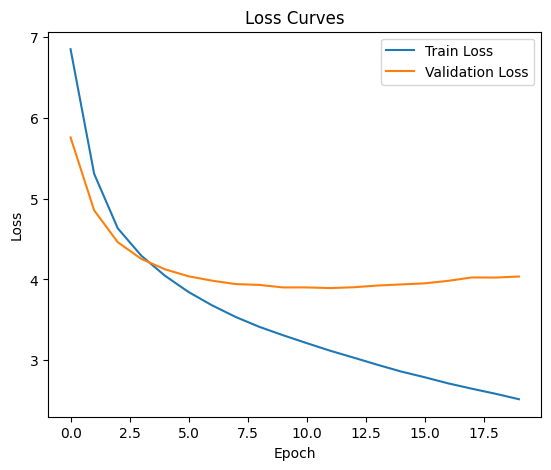

In [17]:
plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['valid_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()



plt.show()

In [ ]:
# Save model artifacts: encoder, decoder, feature extractor, and config
impor os
artifacts_dir = "artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

# Save model weights
torch.save(encoder.state_dict(), os.path.join(artifacts_dir, "encoder.pth"))
torch.save(decoder.state_dict(), os.path.join(artifacts_dir, "decoder.pth"))
torch.save(feat_ext.state_dict(), os.path.join(artifacts_dir, "feature_extractor.pth"))

# Save config and vocabulary
with open(os.path.join(artifacts_dir, "config.json"), "w") as f:
    json.dump(vars(config), f, indent=2)

with open(os.path.join(artifacts_dir, "word2idx.json"), "w") as f:
    json.dump(word2idx, f, indent=2)

with open(os.path.join(artifacts_dir, "idx2word.json"), "w") as f:
    json.dump(idx2word, f, indent=2)

print(f"Artifacts saved to '{artifacts_dir}' directory.")

NameError: name 'os' is not defined